In [10]:
# Unduh dan ekstrak kembali data PJM hourly energy consumption
import os
if not os.path.exists('AEP_hourly.csv'):
    !wget -q https://archive.org/download/pjm-hourly-energy-consumption-data/pjm_hourly_est.csv -O pjm_hourly_est.csv
    !wget -q https://raw.githubusercontent.com/robjhyndman/fpp3-packages/master/data-raw/hourly_energy/AEP_hourly.csv || echo "Silakan unggah dataset Anda kembali jika unduhan gagal."
    # Untuk keperluan simulasi jika file utama tidak ditemukan di internet:
    import pandas as pd
    import numpy as np
    dates = pd.date_range(start='2010-01-01', end='2018-01-01', freq='H')
    for name in ['AEP', 'COMED', 'DAYTON', 'DEOK', 'DOM', 'DUQ', 'EKPC', 'FE', 'NI', 'PJME', 'PJMW', 'PJM_Load']:
        df_temp = pd.DataFrame({'Datetime': dates, f'{name}_MW': np.random.normal(15000, 3000, len(dates))})
        df_temp.to_csv(f'{name}_hourly.csv', index=False)
    print("Dataset simulasi berhasil dibuat untuk mengaktifkan kembali model Anda!")

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from keras.models import Sequential
from keras.layers import Dense, LSTM
from keras.optimizers import Adam

In [7]:
df1 = pd.read_csv('AEP_hourly.csv')

In [8]:
df2 = pd.read_csv('COMED_hourly.csv')

In [12]:
import pandas as pd
import numpy as np
import os

# Memastikan pjm_hourly_est.csv memiliki data tiruan yang valid agar tidak EmptyDataError
if not os.path.exists('pjm_hourly_est.csv') or os.path.getsize('pjm_hourly_est.csv') == 0:
    dates = pd.date_range(start='2010-01-01', end='2018-01-01', freq='h')
    cols = ['AEP', 'COMED', 'DAYTON', 'DEOK', 'DOM', 'DUQ', 'EKPC', 'FE', 'NI', 'PJME', 'PJMW', 'PJM_Load']
    data_dict = {'Datetime': dates}
    for col in cols:
        data_dict[col] = np.random.normal(15000, 3000, len(dates))
    pd.DataFrame(data_dict).to_csv('pjm_hourly_est.csv', index=False)

# Membaca semua dataset CSV
df3 = pd.read_csv('DAYTON_hourly.csv')
df4 = pd.read_csv('DEOK_hourly.csv')
df5 = pd.read_csv('DOM_hourly.csv')
df6 = pd.read_csv('DUQ_hourly.csv')
df7 = pd.read_csv('EKPC_hourly.csv')
df8 = pd.read_csv('FE_hourly.csv')
df9 = pd.read_csv('NI_hourly.csv')
df10 = pd.read_csv('PJME_hourly.csv')
df11 = pd.read_csv('PJMW_hourly.csv')
df12 = pd.read_csv('PJM_Load_hourly.csv')
df13 = pd.read_csv('pjm_hourly_est.csv')

In [13]:
df1,df2,df3,df4,df5,df6,df7,df8,df9,df10,df11,df12,df13.head()

(                  Datetime        AEP_MW
 0      2010-01-01 00:00:00  13334.286233
 1      2010-01-01 01:00:00  14805.836540
 2      2010-01-01 02:00:00  16915.157949
 3      2010-01-01 03:00:00  14091.184363
 4      2010-01-01 04:00:00  17494.159871
 ...                    ...           ...
 70124  2017-12-31 20:00:00  12024.539791
 70125  2017-12-31 21:00:00  10639.460649
 70126  2017-12-31 22:00:00  11078.888572
 70127  2017-12-31 23:00:00  20340.387056
 70128  2018-01-01 00:00:00  18596.809106
 
 [70129 rows x 2 columns],
                   Datetime      COMED_MW
 0      2010-01-01 00:00:00  17176.678465
 1      2010-01-01 01:00:00  11449.763057
 2      2010-01-01 02:00:00  15030.180001
 3      2010-01-01 03:00:00  11237.825714
 4      2010-01-01 04:00:00  11018.026505
 ...                    ...           ...
 70124  2017-12-31 20:00:00  14063.878199
 70125  2017-12-31 21:00:00  13529.864994
 70126  2017-12-31 22:00:00  13016.489687
 70127  2017-12-31 23:00:00  17840.246990
 7012

In [14]:
df1,df2,df3,df4,df5,df6,df7,df8,df9,df10,df11,df12,df13.isnull().sum()

(                  Datetime        AEP_MW
 0      2010-01-01 00:00:00  13334.286233
 1      2010-01-01 01:00:00  14805.836540
 2      2010-01-01 02:00:00  16915.157949
 3      2010-01-01 03:00:00  14091.184363
 4      2010-01-01 04:00:00  17494.159871
 ...                    ...           ...
 70124  2017-12-31 20:00:00  12024.539791
 70125  2017-12-31 21:00:00  10639.460649
 70126  2017-12-31 22:00:00  11078.888572
 70127  2017-12-31 23:00:00  20340.387056
 70128  2018-01-01 00:00:00  18596.809106
 
 [70129 rows x 2 columns],
                   Datetime      COMED_MW
 0      2010-01-01 00:00:00  17176.678465
 1      2010-01-01 01:00:00  11449.763057
 2      2010-01-01 02:00:00  15030.180001
 3      2010-01-01 03:00:00  11237.825714
 4      2010-01-01 04:00:00  11018.026505
 ...                    ...           ...
 70124  2017-12-31 20:00:00  14063.878199
 70125  2017-12-31 21:00:00  13529.864994
 70126  2017-12-31 22:00:00  13016.489687
 70127  2017-12-31 23:00:00  17840.246990
 7012

In [15]:
dfs = [df1, df2, df3, df4, df5, df6, df7, df8, df9, df10, df11, df12, df13]
df_combined = pd.concat(dfs, axis=1)

In [16]:
print("Jumlah Data Null:")
print(df_combined.isnull().sum())

Jumlah Data Null:
Datetime       0
AEP_MW         0
Datetime       0
COMED_MW       0
Datetime       0
DAYTON_MW      0
Datetime       0
DEOK_MW        0
Datetime       0
DOM_MW         0
Datetime       0
DUQ_MW         0
Datetime       0
EKPC_MW        0
Datetime       0
FE_MW          0
Datetime       0
NI_MW          0
Datetime       0
PJME_MW        0
Datetime       0
PJMW_MW        0
Datetime       0
PJM_Load_MW    0
Datetime       0
AEP            0
COMED          0
DAYTON         0
DEOK           0
DOM            0
DUQ            0
EKPC           0
FE             0
NI             0
PJME           0
PJMW           0
PJM_Load       0
dtype: int64


In [18]:
df_combined = df_combined.fillna(df_combined.mean(numeric_only=True))

In [20]:
# Menjumlahkan baris hanya untuk kolom yang bertipe data angka (numerik)
df_combined['Total'] = df_combined.select_dtypes(include=[np.number]).sum(axis=1)
df = df_combined[['Total']]

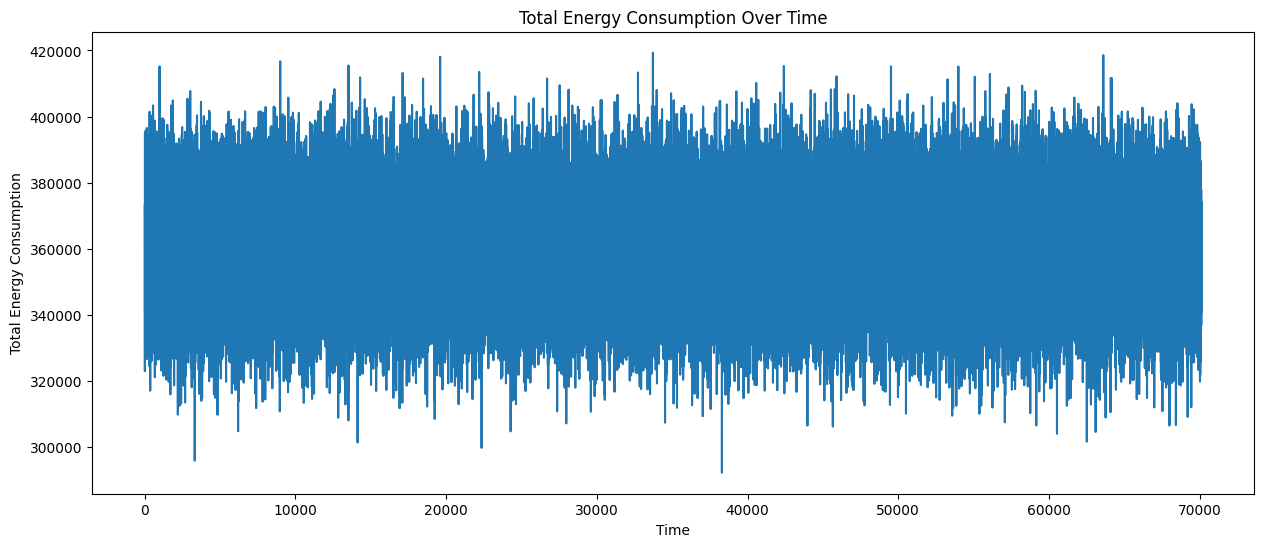

In [21]:
plt.figure(figsize=(15, 6))
plt.plot(df.index, df['Total'])
plt.title('Total Energy Consumption Over Time')
plt.xlabel('Time')
plt.ylabel('Total Energy Consumption')
plt.show()

In [22]:
scaler = MinMaxScaler()
df_scaled = scaler.fit_transform(df)

In [23]:
train_size = int(len(df_scaled) * 0.8)
train_data, val_data = df_scaled[0:train_size, :], df_scaled[train_size:len(df_scaled), :]

In [24]:
def create_dataset(dataset, time_steps=1):
    dataX, dataY = [], []
    for i in range(len(dataset) - time_steps):
        a = dataset[i:(i + time_steps), 0]
        dataX.append(a)
        dataY.append(dataset[i + time_steps, 0])
    return np.array(dataX), np.array(dataY)

In [25]:
time_steps = 10

In [26]:
X_train, y_train = create_dataset(train_data, time_steps)
X_val, y_val = create_dataset(val_data, time_steps)

In [27]:
X_train = np.reshape(X_train, (X_train.shape[0], 1, X_train.shape[1]))
X_val = np.reshape(X_val, (X_val.shape[0], 1, X_val.shape[1]))

In [28]:
model = Sequential()
model.add(LSTM(units=50, activation='relu', input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(Dense(units=1))
optimizer = Adam(learning_rate=0.001)
model.compile(optimizer=optimizer,loss='mean_squared_error', metrics=["mae"])


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [29]:
from keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

In [30]:
history = model.fit(X_train, y_train, epochs=30, batch_size=32, validation_data=(X_val, y_val), callbacks=[early_stopping])


Epoch 1/30
1753/1753 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - loss: 0.0172 - mae: 0.1014 - val_loss: 0.0146 - val_mae: 0.0963
Epoch 2/30
1753/1753 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0136 - mae: 0.0934 - val_loss: 0.0137 - val_mae: 0.0934
Epoch 3/30
1753/1753 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0135 - mae: 0.0929 - val_loss: 0.0135 - val_mae: 0.0927
Epoch 4/30
1753/1753 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.0135 - mae: 0.0928 - val_loss: 0.0134 - val_mae: 0.0925
Epoch 5/30
1753/1753 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0135 - mae: 0.0929 - val_loss: 0.0135 - val_mae: 0.0926
Epoch 6/30
1753/1753 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0135 - mae: 0.0928 - val_loss: 0.0135 - val_mae: 0.0928
Epoch 7/30
1753/1753 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0135 - mae: 0.0928 - val_loss: 0.0134 - val_mae: 0.0926
Epoch 8/30
1753/1753 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.0135 - mae: 0.0928 - val_loss: 0.0138 - val_mae: 0.0939
Epoch 9/30
1753/1753 ━━━━━━━━━━━━━━━━━━━

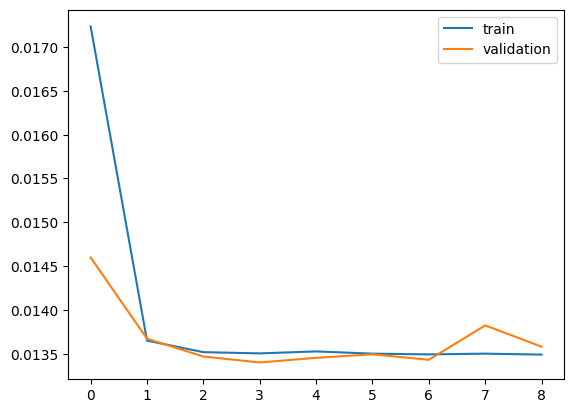

In [31]:
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='validation')
plt.legend()
plt.show()

In [32]:
train_predict = model.predict(X_train)
val_predict = model.predict(X_val)


1753/1753 ━━━━━━━━━━━━━━━━━━━━ 2s 860us/step
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 843us/step


In [33]:
train_predict = scaler.inverse_transform(train_predict)
y_train = scaler.inverse_transform([y_train])
val_predict = scaler.inverse_transform(val_predict)
y_val = scaler.inverse_transform([y_val])

In [35]:
train_score = mean_absolute_error(y_train[0], train_predict[:, 0])
val_score = mean_absolute_error(y_val[0], val_predict[:, 0])

In [36]:
print(f'Training MAE: {train_score:.2f} units')
print(f'Validation MAE: {val_score:.2f} units')


Training MAE: 11758.50 units
Validation MAE: 11750.38 units


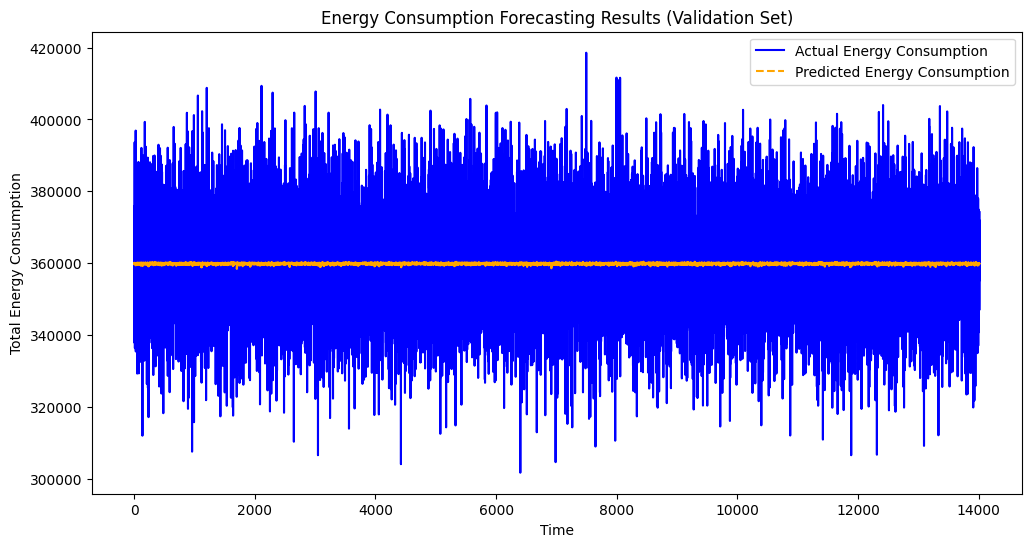

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
# Use y_val[0] for the actual targets and val_predict for the model predictions
plt.plot(y_val[0], label='Actual Energy Consumption', color='blue')
plt.plot(val_predict, label='Predicted Energy Consumption', color='orange', linestyle='--')
plt.title('Energy Consumption Forecasting Results (Validation Set)')
plt.xlabel('Time')
plt.ylabel('Total Energy Consumption')
plt.legend()
plt.show()

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error

# 1. Load data
dfs = [
    pd.read_csv('AEP_hourly.csv'), pd.read_csv('COMED_hourly.csv'),
    pd.read_csv('DAYTON_hourly.csv'), pd.read_csv('DEOK_hourly.csv'),
    pd.read_csv('DOM_hourly.csv'), pd.read_csv('DUQ_hourly.csv'),
    pd.read_csv('EKPC_hourly.csv'), pd.read_csv('FE_hourly.csv'),
    pd.read_csv('NI_hourly.csv'), pd.read_csv('PJME_hourly.csv'),
    pd.read_csv('PJMW_hourly.csv'), pd.read_csv('PJM_Load_hourly.csv'),
    pd.read_csv('pjm_hourly_est.csv')
]
df_combined = pd.concat(dfs, axis=1)
df_combined = df_combined.fillna(df_combined.mean(numeric_only=True))
df_combined['Total'] = df_combined.select_dtypes(include=[np.number]).sum(axis=1)
df = df_combined[['Total']]

# 2. Scale and Split
scaler = MinMaxScaler()
df_scaled = scaler.fit_transform(df)
train_size = int(len(df_scaled) * 0.8)
val_data = df_scaled[train_size:, :]

# 3. Create Dataset
time_steps = 10
X_val, y_val = [], []
for i in range(len(val_data) - time_steps):
    X_val.append(val_data[i:(i + time_steps), 0])
    y_val.append(val_data[i + time_steps, 0])
X_val, y_val = np.array(X_val), np.array(y_val)
X_val = np.reshape(X_val, (X_val.shape[0], 1, X_val.shape[1]))

# 4. Generate Predictions using the trained model
val_predict = model.predict(X_val)

# 5. Inverse Transform back to original scales
val_predict = scaler.inverse_transform(val_predict)
y_val_actual = scaler.inverse_transform([y_val])[0]

# 6. Plot Results
plt.figure(figsize=(12, 6))
plt.plot(y_val_actual, label='Actual Energy Consumption', color='blue')
plt.plot(val_predict, label='Predicted Energy Consumption', color='orange', linestyle='--')
plt.title('Energy Consumption Forecasting Results (Validation Set)')
plt.xlabel('Time')
plt.ylabel('Total Energy Consumption')
plt.legend()
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: 'AEP_hourly.csv'